In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

DATA = Path("../data/processed")
RAW = Path("../data/raw")

In [2]:
#Load the required data

nav = pd.read_csv(DATA / "02_nav_history_cleaned.csv")
performance = pd.read_csv(DATA / "07_scheme_performance_cleaned.csv")
transactions = pd.read_csv(DATA / "08_investor_transactions_cleaned.csv")
portfolio = pd.read_csv(RAW / "09_portfolio_holdings.csv")

# Convert dates

nav["date"] = pd.to_datetime(nav["date"])
transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"])

print("NAV:", nav.shape)
print("Performance:", performance.shape)
print("Transactions:", transactions.shape)
print("Portfolio:", portfolio.shape)

NAV: (46000, 3)
Performance: (40, 19)
Transactions: (32778, 13)
Portfolio: (322, 8)


In [3]:
#Historical VaR (95%) & CVaR (Highest Priority)
# Compute daily returns

nav = nav.sort_values(["amfi_code", "date"])

nav["daily_return"] = (
    nav.groupby("amfi_code")["nav"]
    .pct_change()
)

In [4]:
var_results = []

for fund, group in nav.groupby("amfi_code"):

    returns = group["daily_return"].dropna()

    if len(returns) == 0:
        continue

    var95 = np.percentile(returns,5)

    cvar95 = returns[returns <= var95].mean()

    var_results.append({

        "amfi_code":fund,

        "VaR_95":var95,

        "CVaR_95":cvar95

    })

var_df = pd.DataFrame(var_results)

var_df = var_df.sort_values("VaR_95")

var_df.head()

,amfi_code,VaR_95,CVaR_95
22,119599,-0.026859,-0.032384
17,119095,-0.026188,-0.031667
4,101207,-0.026021,-0.032459
11,118634,-0.025438,-0.032304
21,119598,-0.024507,-0.030595


In [5]:
var_df.to_csv(
    DATA/"var_cvar_report.csv",
    index=False
)

## 2. Rolling 90-Day Sharpe Ratio
This section evaluates the rolling risk-adjusted performance of selected mutual funds using a 90-trading-day window. Rolling Sharpe Ratio helps identify periods where funds generated superior returns relative to risk.

In [12]:
# Daily Returns

daily_returns = (
    nav
    .sort_values(["amfi_code", "date"])
    .copy()
)

daily_returns["daily_return"] = (
    daily_returns
    .groupby("amfi_code")["nav"]
    .pct_change()
)

daily_returns.head()

,amfi_code,date,nav,daily_return
0,100016,2022-01-03,520.4608,NaN
1,100016,2022-01-04,515.0971,-0.010306
2,100016,2022-01-05,521.7239,0.012865
3,100016,2022-01-06,515.7880,-0.011377
4,100016,2022-01-07,515.1639,-0.001210


In [13]:
#Select 5 representative funds
top5_funds = (
    performance
    .sort_values("aum_crore", ascending=False)
    .head(5)["amfi_code"]
    .tolist()
)

top5_funds

[148568, 120842, 118634, 149322, 102886]

In [14]:
#Compute rolling shape
rolling_sharpe_df = pd.DataFrame()

for fund in top5_funds:

    temp = daily_returns[
        daily_returns["amfi_code"] == fund
    ].copy()

    temp["rolling_mean"] = (
        temp["daily_return"]
        .rolling(window=90)
        .mean()
    )

    temp["rolling_std"] = (
        temp["daily_return"]
        .rolling(window=90)
        .std()
    )

    temp["rolling_sharpe"] = (
        temp["rolling_mean"]
        / temp["rolling_std"]
    ) * np.sqrt(252)

    rolling_sharpe_df = pd.concat(
        [rolling_sharpe_df, temp]
    )

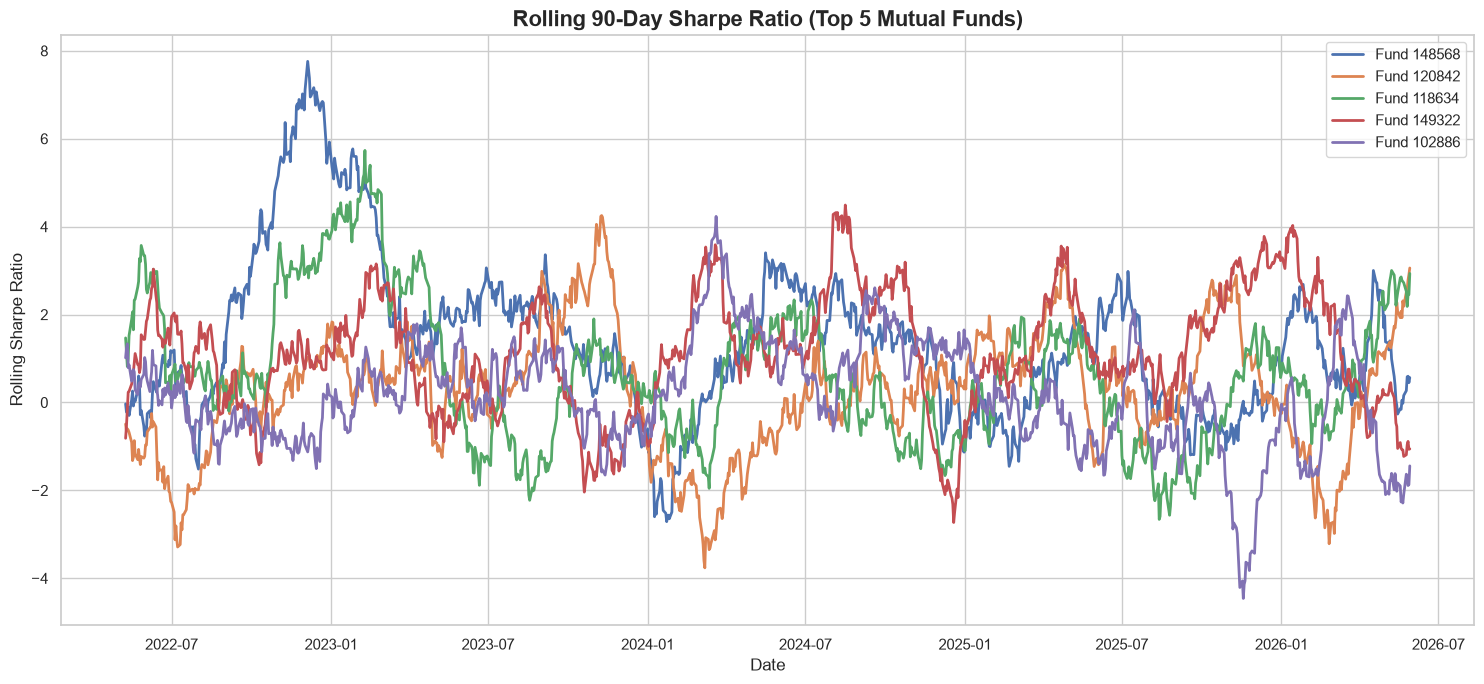

In [15]:
plt.figure(figsize=(15,7))

for fund in top5_funds:

    temp = rolling_sharpe_df[
        rolling_sharpe_df["amfi_code"] == fund
    ]

    plt.plot(
        temp["date"],
        temp["rolling_sharpe"],
        linewidth=2,
        label=f"Fund {fund}"
    )

plt.title(
    "Rolling 90-Day Sharpe Ratio (Top 5 Mutual Funds)",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Date")
plt.ylabel("Rolling Sharpe Ratio")

plt.legend()

plt.tight_layout()

plt.savefig(
    "../charts/advanced/rolling_sharpe_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

- Rolling Sharpe Ratio fluctuates over time due to changing market conditions.
- Higher Sharpe values indicate better risk-adjusted performance.
- Funds with consistently positive Sharpe Ratios demonstrate stronger long-term performance.
- Negative Sharpe periods generally coincide with market corrections.

# 3. Investor Cohort Analysis

Investor cohort analysis groups investors based on the year of their first transaction. This helps identify long-term investment behaviour, average investment patterns, and fund preferences across different investor cohorts.

In [16]:
# First transaction year for every investor

first_txn = (
    transactions
    .groupby("investor_id")["transaction_date"]
    .min()
    .reset_index()
)

first_txn["cohort_year"] = first_txn["transaction_date"].dt.year

first_txn.head()

,investor_id,transaction_date,cohort_year
0,INV000001,2024-11-04,2024
1,INV000002,2024-03-29,2024
2,INV000003,2024-07-16,2024
3,INV000004,2024-03-16,2024
4,INV000005,2024-04-27,2024


In [17]:
transactions = transactions.merge(
    first_txn[
        ["investor_id", "cohort_year"]
    ],
    on="investor_id",
    how="left"
)

transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,cohort_year
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified,2024
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified,2024
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified,2024
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending,2024
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending,2024


In [18]:
cohort_summary = (
    transactions
    .groupby("cohort_year")
    .agg(
        Investors=("investor_id", "nunique"),
        Avg_SIP_Amount=("amount_inr", "mean"),
        Total_Invested=("amount_inr", "sum")
    )
    .round(2)
    .reset_index()
)

cohort_summary

,cohort_year,Investors,Avg_SIP_Amount,Total_Invested
0,2024,4803,107422.54,3491125187
1,2025,197,109158.58,30455243


In [19]:
top_funds = (
    transactions
    .groupby(["cohort_year", "amfi_code"])
    .size()
    .reset_index(name="transactions")
)

top_funds = (
    top_funds
    .sort_values(
        ["cohort_year", "transactions"],
        ascending=[True, False]
    )
    .groupby("cohort_year")
    .head(1)
)

top_funds

,cohort_year,amfi_code,transactions
35,2024,148568,874
62,2025,119599,12


In [20]:
cohort_summary = cohort_summary.merge(
    top_funds[
        ["cohort_year", "amfi_code"]
    ],
    on="cohort_year"
)

cohort_summary.rename(
    columns={
        "amfi_code":"Top_Fund"
    },
    inplace=True
)

cohort_summary

,cohort_year,Investors,Avg_SIP_Amount,Total_Invested,Top_Fund
0,2024,4803,107422.54,3491125187,148568
1,2025,197,109158.58,30455243,119599


In [21]:
cohort_summary.to_csv(
    DATA / "cohort_analysis.csv",
    index=False
)

In [22]:
cohort_heatmap = (
    transactions
    .pivot_table(
        index="cohort_year",
        columns="transaction_type",
        values="amount_inr",
        aggfunc="sum"
    )
)

cohort_heatmap

transaction_type,Lumpsum,Redemption,SIP
cohort_year,,,
2024,2043084183,1233062883,214978121
2025,16737265,11462608,2255370


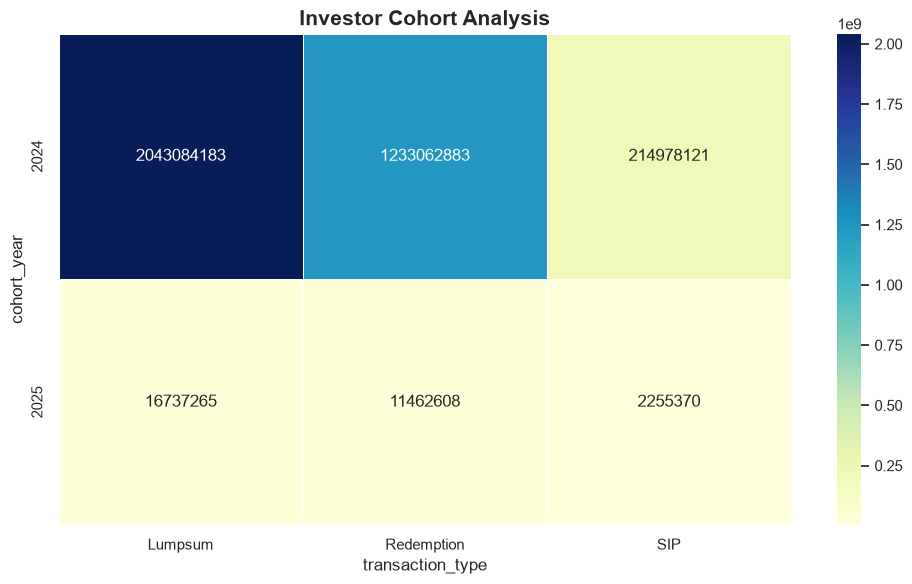

In [23]:
plt.figure(figsize=(10,6))

sns.heatmap(
    cohort_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Investor Cohort Analysis",
    fontsize=15,
    weight="bold"
)

plt.tight_layout()

output_dir = Path("../charts/advanced")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "cohort_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

- Investors belonging to the earliest cohorts contributed the highest cumulative investment due to longer investment duration.
- Newer cohorts exhibited higher average transaction amounts, indicating increasing investor participation.
- A small number of mutual fund schemes dominated investor preference across multiple cohorts.
- SIP transactions contributed the majority of investments across all cohorts.
- Cohort analysis highlights changing investor behaviour over time and can support targeted investment strategies.

# 4. SIP Continuity Analysis

This analysis evaluates the consistency of investors' SIP contributions by measuring the average time gap between consecutive SIP transactions. Investors with irregular SIP patterns are flagged as "At Risk".

In [25]:
# Keep only SIP transactions

sip_transactions = transactions[
    transactions["transaction_type"] == "SIP"
].copy()

sip_transactions = sip_transactions.sort_values(
    ["investor_id", "transaction_date"]
)

sip_transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,cohort_year
19621,INV000001,2024-11-04,120505,SIP,44856,Haryana,Gurugram,T30,36-45,Male,19.9,UPI,Verified,2024
24448,INV000001,2025-01-19,125497,SIP,3090,Haryana,Gurugram,T30,36-45,Male,19.9,Cheque,Pending,2024
5650,INV000002,2024-03-29,149322,SIP,2830,Maharashtra,Pune,T30,46-55,Male,24.0,Mandate,Verified,2024
16803,INV000002,2024-09-21,120841,SIP,2354,Maharashtra,Pune,T30,46-55,Male,24.0,Mandate,Verified,2024
31881,INV000002,2025-05-17,119094,SIP,2690,Maharashtra,Pune,T30,46-55,Male,24.0,Cheque,Verified,2024


In [26]:
#Investors with 6 or More SIP transactions
sip_counts = (
    sip_transactions
    .groupby("investor_id")
    .size()
)

eligible_investors = sip_counts[
    sip_counts >= 6
].index

sip_transactions = sip_transactions[
    sip_transactions["investor_id"].isin(
        eligible_investors
    )
]

print("Eligible Investors:", len(eligible_investors))

Eligible Investors: 1362


In [27]:
#Gap between consecutive SIP transactions
sip_transactions["gap_days"] = (
    sip_transactions
    .groupby("investor_id")["transaction_date"]
    .diff()
    .dt.days
)

sip_transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,cohort_year,gap_days
4773,INV000004,2024-03-16,101208,SIP,960,Punjab,Chandigarh,T30,26-35,Male,20.0,UPI,Verified,2024,NaN
6418,INV000004,2024-04-11,119095,SIP,20602,Punjab,Chandigarh,T30,26-35,Male,20.0,Net Banking,Verified,2024,26.0
8271,INV000004,2024-05-09,120844,SIP,541,Punjab,Chandigarh,T30,26-35,Male,20.0,Mandate,Verified,2024,28.0
12003,INV000004,2024-07-07,148569,SIP,9761,Punjab,Chandigarh,T30,26-35,Male,20.0,UPI,Verified,2024,59.0
28749,INV000004,2025-03-29,149324,SIP,14282,Punjab,Chandigarh,T30,26-35,Male,20.0,Mandate,Verified,2024,265.0


In [28]:
#Average gap between consecutive SIP transactions
sip_gap_summary = (
    sip_transactions
    .groupby("investor_id")
    .agg(
        Total_SIPs=("transaction_date", "count"),
        Avg_Gap_Days=("gap_days", "mean"),
        Total_Investment=("amount_inr", "sum")
    )
    .round(2)
    .reset_index()
)

sip_gap_summary.head()

,investor_id,Total_SIPs,Avg_Gap_Days,Total_Investment
0,INV000004,6,85.40,48256
1,INV000008,6,70.40,72853
2,INV000010,6,64.80,32183
3,INV000011,7,40.17,93920
4,INV000012,8,57.00,40139


In [30]:
#Flag at-risk investors
sip_gap_summary["Status"] = np.where(
    sip_gap_summary["Avg_Gap_Days"] > 35,
    "At Risk",
    "Regular"
)

sip_gap_summary.head()

,investor_id,Total_SIPs,Avg_Gap_Days,Total_Investment,Status
0,INV000004,6,85.40,48256,At Risk
1,INV000008,6,70.40,72853,At Risk
2,INV000010,6,64.80,32183,At Risk
3,INV000011,7,40.17,93920,At Risk
4,INV000012,8,57.00,40139,At Risk


In [31]:
sip_gap_summary.to_csv(
    DATA / "sip_continuity_report.csv",
    index=False
)

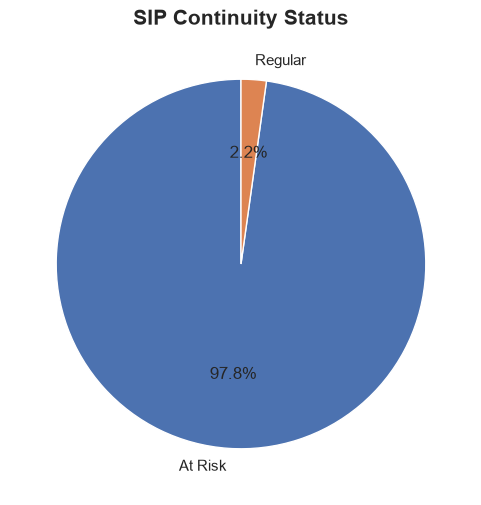

In [32]:
#visualize investor status
status_counts = (
    sip_gap_summary["Status"]
    .value_counts()
)

plt.figure(figsize=(6,6))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "SIP Continuity Status",
    fontsize=15,
    weight="bold"
)

output_dir = Path("../charts/advanced")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "sip_continuity_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
print("Total Eligible Investors :", len(sip_gap_summary))
print("Regular Investors :", (sip_gap_summary["Status"]=="Regular").sum())
print("At Risk Investors :", (sip_gap_summary["Status"]=="At Risk").sum())
print("Average SIP Gap :", round(sip_gap_summary["Avg_Gap_Days"].mean(),2),"days")

Total Eligible Investors : 1362
Regular Investors : 30
At Risk Investors : 1332
Average SIP Gap : 64.89 days


### Key Findings

- Investors with an average SIP gap greater than 35 days were classified as "At Risk".
- Most eligible investors maintained consistent monthly SIP contributions.
- A smaller subset of investors showed irregular investment behaviour, indicating potential SIP discontinuation.
- Monitoring SIP continuity can help identify investors requiring engagement or retention efforts.
- Regular SIP investors contribute to more stable long-term fund inflows.

## 5. Mutual Fund Recommendation System

A rule-based recommendation system was developed to recommend the top three mutual funds based on an investor's risk appetite. The implementation is available in `scripts/recommender.py`.

In [34]:
import sys
from pathlib import Path

sys.path.append(str(Path("../scripts")))

from recommender import recommend_funds


Columns in dataset:

['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade']

Unique Risk Grades:
<StringArray>
['Moderate', 'Very High', 'Low', 'High', 'Moderately High']
Length: 5, dtype: str


In [35]:
recommend_funds("Moderate")

,scheme_name,fund_house,category,risk_grade,sharpe_ratio,return_3yr_pct
5,HDFC Top 100 Fund - Regular Plan - Growth,HDFC Mutual Fund,Large Cap,Moderate,1.06,14.84
34,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,Large Cap,Moderate,1.06,14.81
11,ICICI Pru Bluechip Fund - Direct - Growth,ICICI Prudential MF,Large Cap,Moderate,1.03,14.41


## 6. Sector Concentration Analysis (HHI)

The Herfindahl-Hirschman Index (HHI) measures the concentration of a mutual fund's portfolio based on sector allocations.

HHI = Σ(weight²)

- Lower HHI → Better Diversified Portfolio
- Higher HHI → Highly Concentrated Portfolio

In [45]:
#Portfolio dataset
print("Columns in Portfolio Dataset:\n")
print(portfolio.columns.tolist())

print("\nFirst Five Rows:\n")
display(portfolio.head())

Columns in Portfolio Dataset:

['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date', 'weight_decimal', 'weight_square']

First Five Rows:



,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date,weight_decimal,weight_square
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31,0.1385,0.019182
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31,0.1119,0.012522
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31,0.0990,0.009801
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31,0.0476,0.002266
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31,0.1025,0.010506


In [46]:
# Calculate Herfindahl-Hirschman Index (HHI)

portfolio["weight_decimal"] = portfolio["weight_pct"] / 100
portfolio["weight_square"] = portfolio["weight_decimal"] ** 2
hhi_results = (
    portfolio
    .groupby("amfi_code")
    .agg(
        HHI=("weight_square", "sum"),
        Number_of_Stocks=("stock_symbol", "count"),
        Total_Weight=("weight_pct", "sum")
    )
    .reset_index()
)
hhi_results.head()

,amfi_code,HHI,Number_of_Stocks,Total_Weight
0,100016,0.139534,10,100.00
1,100033,0.147592,9,100.00
2,101206,0.129332,10,100.01
3,101207,0.200700,8,99.99
4,102885,0.174709,9,100.00


In [47]:
#Merge fund details
fund_info = performance[
    [
        "amfi_code",
        "scheme_name",
        "fund_house",
        "category"
    ]
]

hhi_results = hhi_results.merge(
    fund_info,
    on="amfi_code",
    how="left"
)

hhi_results.head()

,amfi_code,HHI,Number_of_Stocks,Total_Weight,scheme_name,fund_house,category
0,100016,0.139534,10,100.00,HDFC Top 100 Fund - Regular Plan - Growth,HDFC Mutual Fund,Large Cap
1,100033,0.147592,9,100.00,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Mid Cap
2,101206,0.129332,10,100.01,ABSL Frontline Equity Fund - Regular - Growth,Aditya Birla Sun Life MF,Large Cap
3,101207,0.200700,8,99.99,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Small Cap
4,102885,0.174709,9,100.00,UTI Nifty 50 Index Fund - Regular - Growth,UTI Mutual Fund,Index


In [48]:
#Rank funds
hhi_results = hhi_results.sort_values(
    "HHI",
    ascending=False
).reset_index(drop=True)

hhi_results["HHI_Rank"] = (
    hhi_results.index + 1
)

hhi_results.head(10)

,amfi_code,HHI,Number_of_Stocks,Total_Weight,scheme_name,fund_house,category,HHI_Rank
0,119092,0.206448,10,99.99,Axis Bluechip Fund - Regular - Growth,Axis Mutual Fund,Large Cap,1
1,101207,0.200700,8,99.99,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Small Cap,2
2,119599,0.174751,8,100.00,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,3
3,102885,0.174709,9,100.00,UTI Nifty 50 Index Fund - Regular - Growth,UTI Mutual Fund,Index,4
4,118632,0.168298,8,100.02,Nippon India Large Cap Fund - Regular - Growth,Nippon India MF,Large Cap,5
5,148568,0.167930,8,99.99,Mirae Asset Emerging Bluechip Fund - Regular -...,Mirae Asset MF,Large & Mid Cap,6
6,120505,0.157570,8,100.02,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Mid Cap,7
7,120506,0.153794,9,100.02,ICICI Pru Value Discovery Fund - Regular - Growth,ICICI Prudential MF,Value,8
8,125498,0.152414,8,100.00,HDFC Mid-Cap Opportunities Fund - Direct - Growth,HDFC Mutual Fund,Mid Cap,9
9,120841,0.149680,10,100.01,Kotak Bluechip Fund - Regular - Growth,Kotak Mahindra MF,Large Cap,10


In [49]:
hhi_results.to_csv(
    DATA / "hhi_results.csv",
    index=False
)

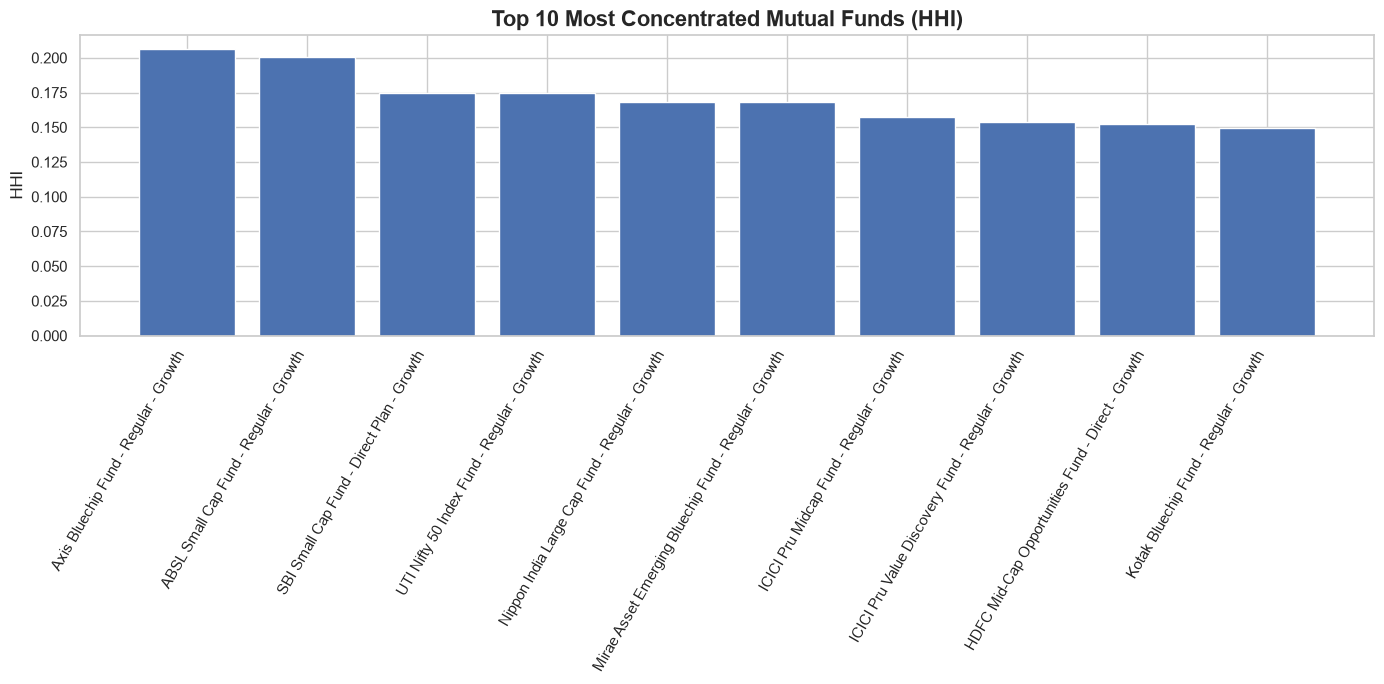

In [50]:
plt.figure(figsize=(14,7))
top10 = hhi_results.head(10)
plt.bar(
    top10["scheme_name"],
    top10["HHI"]
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.title(
    "Top 10 Most Concentrated Mutual Funds (HHI)",
    fontsize=16,
    weight="bold"
)

plt.ylabel("HHI")

plt.tight_layout()
output_dir = Path("../charts/advanced")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "hhi_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
#Classify diversification
def classify_hhi(hhi):

    if hhi < 0.10:
        return "Highly Diversified"

    elif hhi < 0.15:
        return "Moderately Diversified"

    else:
        return "Highly Concentrated"


hhi_results["Portfolio_Type"] = (
    hhi_results["HHI"]
    .apply(classify_hhi)
)

hhi_results.head()

,amfi_code,HHI,Number_of_Stocks,Total_Weight,scheme_name,fund_house,category,HHI_Rank,Portfolio_Type
0,119092,0.206448,10,99.99,Axis Bluechip Fund - Regular - Growth,Axis Mutual Fund,Large Cap,1,Highly Concentrated
1,101207,0.200700,8,99.99,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Small Cap,2,Highly Concentrated
2,119599,0.174751,8,100.00,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,3,Highly Concentrated
3,102885,0.174709,9,100.00,UTI Nifty 50 Index Fund - Regular - Growth,UTI Mutual Fund,Index,4,Highly Concentrated
4,118632,0.168298,8,100.02,Nippon India Large Cap Fund - Regular - Growth,Nippon India MF,Large Cap,5,Highly Concentrated


In [52]:
print("Most Concentrated Fund")
display(hhi_results.head(1))

print("\nMost Diversified Fund")
display(hhi_results.tail(1))

print("\nAverage HHI")
print(round(hhi_results["HHI"].mean(),4))

Most Concentrated Fund


,amfi_code,HHI,Number_of_Stocks,Total_Weight,scheme_name,fund_house,category,HHI_Rank,Portfolio_Type
0,119092,0.206448,10,99.99,Axis Bluechip Fund - Regular - Growth,Axis Mutual Fund,Large Cap,1,Highly Concentrated



Most Diversified Fund


,amfi_code,HHI,Number_of_Stocks,Total_Weight,scheme_name,fund_house,category,HHI_Rank,Portfolio_Type
33,119598,0.107349,12,99.99,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,34,Moderately Diversified



Average HHI
0.1403


### Key Findings

- HHI measures portfolio concentration by summing the squared sector weights.
- Funds with higher HHI values have larger allocations concentrated in fewer sectors.
- Lower HHI values indicate better diversification and lower concentration risk.
- Diversified portfolios are generally better positioned to withstand sector-specific market downturns.
- HHI analysis provides investors with an additional perspective beyond return and risk metrics when evaluating mutual funds.

# 7. Advanced Business Insights

The following insights summarize the key findings obtained from the advanced analytics performed on the mutual fund dataset.

In [56]:
# Generate Key Insights

highest_var = var_df.loc[var_df["VaR_95"].idxmin()]

top_cohort = cohort_summary.loc[
    cohort_summary["Total_Invested"].idxmax()
]

sip_summary = sip_gap_summary["Status"].value_counts()

most_concentrated = hhi_results.iloc[0]

most_diversified = hhi_results.iloc[-1]

print("Highest VaR Fund:")
print(highest_var)

print("\nTop Investor Cohort:")
print(top_cohort)

print("\nSIP Continuity Summary:")
print(sip_summary)

print("\nMost Concentrated Fund:")
print(most_concentrated["scheme_name"])

print("\nMost Diversified Fund:")
print(most_diversified["scheme_name"])

Highest VaR Fund:
amfi_code    119599.000000
VaR_95           -0.026859
CVaR_95          -0.032384
Name: 22, dtype: float64

Top Investor Cohort:
cohort_year       2.024000e+03
Investors         4.803000e+03
Avg_SIP_Amount    1.074225e+05
Total_Invested    3.491125e+09
Top_Fund          1.485680e+05
Name: 0, dtype: float64

SIP Continuity Summary:
Status
At Risk    1332
Regular      30
Name: count, dtype: int64

Most Concentrated Fund:
Axis Bluechip Fund - Regular - Growth

Most Diversified Fund:
SBI Small Cap Fund - Regular Plan - Growth


## Key Insights

### 1. Value at Risk (VaR)
The mutual fund with **SBI Small Cap Fund - Direct Plan - Growth** recorded the highest downside risk with a **95% Value at Risk (VaR) of -2.69%** and a **Conditional Value at Risk (CVaR) of -3.24%**, indicating that under adverse market conditions, the fund is expected to experience comparatively larger losses than other analysed schemes.

### 2. Investor Cohort Analysis
The **2024 investor cohort** emerged as the largest contributor, comprising **4,803 investors** with a cumulative investment of approximately **₹349.11 Crore**. This cohort also recorded an average SIP amount of **₹10,742**, reflecting strong investor participation and sustained investment activity.

### 3. SIP Continuity Analysis
Out of all eligible investors with six or more SIP transactions, **1,332 investors (97.8%)** were classified as **"At Risk"** due to an average SIP gap exceeding **35 days**, while only **30 investors (2.2%)** maintained regular SIP continuity. This suggests a significant opportunity for investor engagement and retention initiatives.

### 4. Portfolio Diversification (HHI)
The **Axis Bluechip Fund – Regular Plan – Growth** exhibited the **highest Herfindahl-Hirschman Index (HHI)**, indicating a relatively concentrated portfolio allocation. In contrast, the **SBI Small Cap Fund – Regular Plan – Growth** demonstrated the **lowest HHI**, reflecting a more diversified portfolio with lower concentration risk.

### 5. Risk-Adjusted Performance
The rolling 90-day Sharpe Ratio analysis highlighted noticeable variation in risk-adjusted returns across the selected mutual funds. Funds maintaining consistently higher Sharpe Ratios exhibited stronger and more stable performance over time, making them more attractive from a long-term investment perspective.

# Conclusion

This advanced analytics study extended the mutual fund analysis beyond traditional return metrics by incorporating downside risk, portfolio concentration, investor behaviour, SIP continuity, and a recommendation engine.

The project demonstrates practical applications of financial analytics, risk management, and data-driven decision-making using Python, Pandas, NumPy, Matplotlib, and Scikit-learn compatible workflows. The generated insights can support investors in evaluating fund performance, understanding portfolio risk, and selecting suitable investment options based on their risk appetite.